In [1]:
import os

import akshare_proxy_patch
from dotenv import load_dotenv

load_dotenv()
auth_token = os.getenv("AKSHARE_PROXY_AUTH_TOKEN")

akshare_proxy_patch.install_patch(
    "101.201.173.125",
    auth_token=auth_token,
    retry=30,
    hook_domains=["push2his.eastmoney.com"],
    fast=True,
)

In [2]:
from datetime import date

import akshare as ak
import pandas as pd

In [3]:
# Customization
symbol = "515180"
moving_average_window = 120
buy_deviation_threshold = 0.07
sell_deviation_threshold = 0.10

In [4]:
df = ak.fund_etf_hist_em(
    symbol=symbol,
    period="daily",
    start_date="19700101",
    end_date=date.today().strftime("%Y%m%d"),
    adjust="qfq",
)

df["日期"] = pd.to_datetime(df["日期"])
df = df.sort_values("日期").reset_index(drop=True)

df["MA"] = (
    df["收盘"]
    .rolling(window=moving_average_window, min_periods=moving_average_window)
    .mean()
)
df["偏离度"] = df["收盘"] / df["MA"] - 1
df_valid = df.dropna(subset=["MA"]).copy()

In [5]:
buy_signals = df_valid[df_valid["偏离度"] < -buy_deviation_threshold].copy()
sell_signals = df_valid[df_valid["偏离度"] > sell_deviation_threshold].copy()

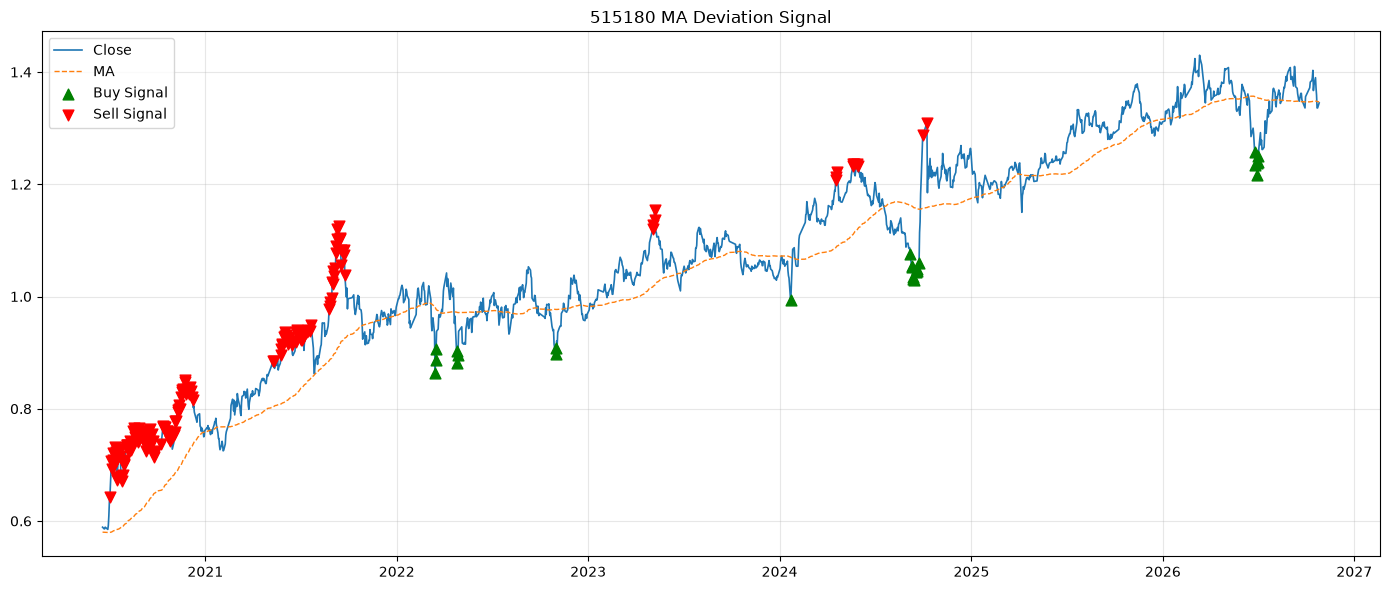

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(df_valid["日期"], df_valid["收盘"], label="Close", linewidth=1.2)
ax.plot(df_valid["日期"], df_valid["MA"], label="MA", linewidth=1.0, linestyle="--")
ax.scatter(
    buy_signals["日期"],
    buy_signals["收盘"],
    color="green",
    marker="^",
    s=60,
    label="Buy Signal",
    zorder=5,
)
ax.scatter(
    sell_signals["日期"],
    sell_signals["收盘"],
    color="red",
    marker="v",
    s=60,
    label="Sell Signal",
    zorder=5,
)
ax.set_title(f"{symbol} MA Deviation Signal")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()